In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print("Shape:", df.shape)

print("\n",df.head())

print(df.info())

print(df.isnull().sum())

print(df['Churn'].value_counts())
churn_rate = df['Churn'].value_counts(normalize=True)[1]
print(f"Churn rate: {churn_rate:.2%}")

Shape: (7043, 21)

    customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies 

/tmp/ipykernel_1182/3116529224.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  churn_rate = df['Churn'].value_counts(normalize=True)[1]


In [ ]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


Missing TotalCharges after conversion: 11
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
3331       0           19.85           NaN
3826       0           25.35           NaN
4380       0           20.00           NaN
5218       0           19.70           NaN
6670       0           73.35           NaN
6754       0           61.90           NaN


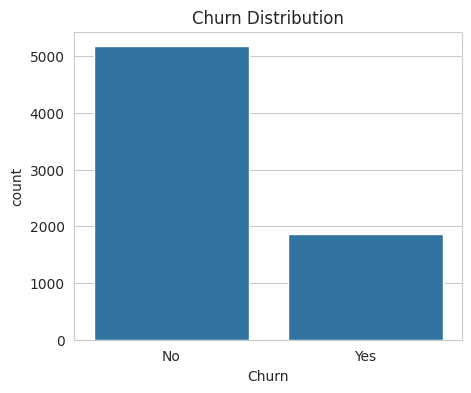

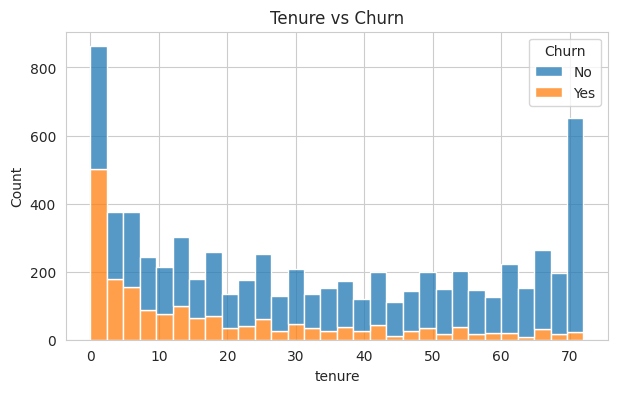

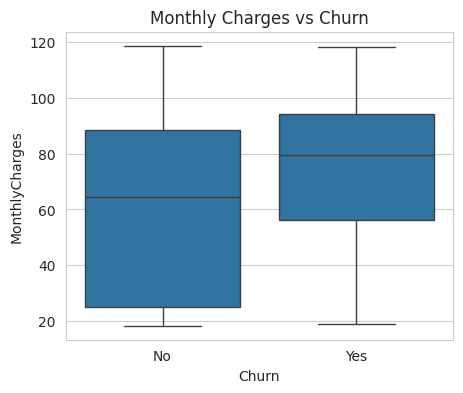

In [ ]:
# ============================================
# STEP 2: Fix TotalCharges + clean + first plots
# ============================================

# TODO 1: Force TotalCharges to numeric. Any value that can't convert becomes NaN.
# This is how we "unmask" the hidden missing values from Step 1.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# TODO 2: Now check — how many actual NaNs appeared after conversion?
print("Missing TotalCharges after conversion:", df['TotalCharges'].isnull().sum())

# TODO 3: Look at the rows where TotalCharges is now NaN.
# Check their 'tenure' column — what do you notice? (hint: think about what TotalCharges even means)
print(df[df['TotalCharges'].isnull()][['tenure', 'MonthlyCharges', 'TotalCharges']])

# TODO 4: Since these are a tiny fraction of 7043 rows, fill them with 0
# (reasoning: tenure=0 means brand new customer, so they haven't been charged a total yet)
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# TODO 5: Drop customerID — it's just a unique identifier, carries zero predictive signal
df = df.drop(columns=['customerID'])

# TODO 6: Plot churn distribution (bar plot) to visually confirm the imbalance we calculated
plt.figure(figsize=(5,4))
sns.countplot(data=df, x='Churn')
plt.title("Churn Distribution")
plt.show()

# TODO 7: Plot tenure distribution split by churn (are new customers more likely to churn?)
plt.figure(figsize=(7,4))
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', bins=30)
plt.title("Tenure vs Churn")
plt.show()

# TODO 8: Plot MonthlyCharges split by churn using a boxplot
plt.figure(figsize=(5,4))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.title("Monthly Charges vs Churn")
plt.show()

bool       21
int64       8
float64     2
Name: count, dtype: int64
Churn                                    1.000000
InternetService_Fiber optic              0.308020
PaymentMethod_Electronic check           0.301919
MonthlyCharges                           0.193356
PaperlessBilling                         0.191825
SeniorCitizen                            0.150889
StreamingTV_Yes                          0.063228
StreamingMovies_Yes                      0.061382
MultipleLines_Yes                        0.040102
PhoneService                             0.011942
gender                                  -0.008612
MultipleLines_No phone service          -0.011942
DeviceProtection_Yes                    -0.066160
OnlineBackup_Yes                        -0.082255
PaymentMethod_Mailed check              -0.091683
PaymentMethod_Credit card (automatic)   -0.134302
Partner                                 -0.150448
Dependents                              -0.164221
TechSupport_Yes                 

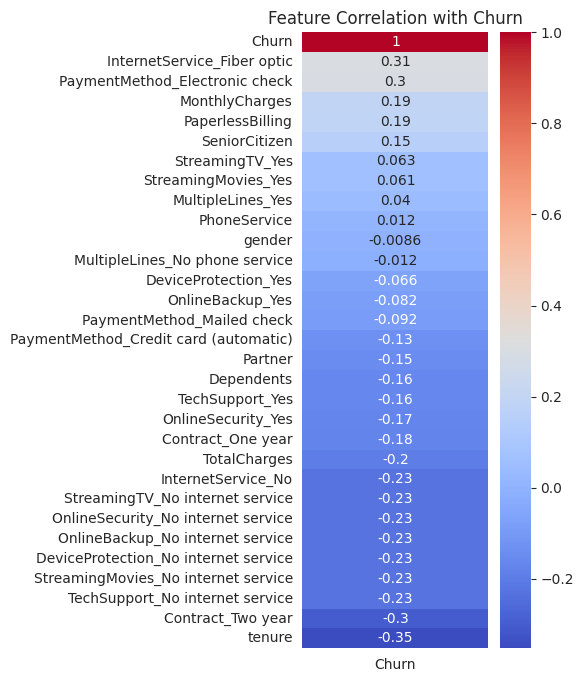

Train shape: (5634, 30) Test shape: (1409, 30)
Train churn rate: 0.2653532126375577 Test churn rate: 0.2654364797728886


In [ ]:
# ============================================
# STEP 3: Encoding + correlation + split
# ============================================

# TODO 1: Convert the target column to 0/1 (models need numbers, not strings)
# 'No' -> 0, 'Yes' -> 1
df['Churn'] = df['Churn'].map({"Yes" : 1,"No" : 0})

# TODO 2: Separate binary Yes/No columns from multi-category columns
# Binary cols (2 unique values like Yes/No) -> Label Encoding (0/1) is fine
# Multi-category cols (like InternetService: DSL/Fiber optic/No) -> One-Hot Encoding
# because label encoding would falsely imply an order (0 < 1 < 2) between categories that have no order

binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']

# TODO 3: Label encode the binary columns using sklearn's LabelEncoder
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in binary_cols:
    df[col] = le.fit_transform(df[col])

# TODO 4: One-hot encode the remaining categorical (multi-class) columns using pd.get_dummies
# drop_first=True avoids the "dummy variable trap" (multicollinearity between dummy columns)
multi_cat_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
                   'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
                   'Contract', 'PaymentMethod']

df = pd.get_dummies(df, columns=multi_cat_cols, drop_first=True)

# TODO 5: Confirm no object dtype columns remain (everything should be numeric now)
print(df.dtypes.value_counts())

# TODO 6: Plot a correlation heatmap of all features against Churn
# (only look at correlation with the TARGET for now, full matrix comes later in feature selection)
plt.figure(figsize=(3,8))
corr_with_target = df.corr()['Churn'].sort_values(ascending=False)
print(corr_with_target)
sns.heatmap(corr_with_target.to_frame(), annot=True, cmap='coolwarm')
plt.title("Feature Correlation with Churn")
plt.show()

# TODO 7: Train-test split — 80/20, stratified on Churn (important! keeps the 26.54% churn ratio
# the same in both train and test sets, since our data is imbalanced)
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Train churn rate:", y_train.mean(), "Test churn rate:", y_test.mean())

                     Accuracy  Precision  Recall     F1  ROC-AUC
Logistic Regression     0.807      0.658   0.567  0.609    0.842
KNN                     0.747      0.525   0.500  0.512    0.772
Random Forest           0.784      0.622   0.479  0.541    0.822


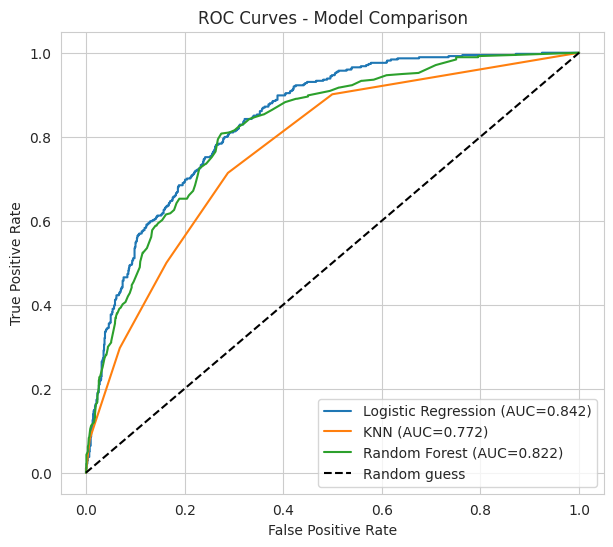

In [ ]:
# ============================================
# STEP 4: Scaling + Baseline Models + Evaluation
# ============================================
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, roc_curve, confusion_matrix,
                              ConfusionMatrixDisplay)

# TODO 1: Scale the features.
# IMPORTANT: fit the scaler ONLY on X_train, then use that SAME fitted scaler on X_test.
# Why? If you fit on the full dataset (train+test combined), information about the test set
# "leaks" into training via the mean/std used for scaling — this is called DATA LEAKAGE.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)   # note: transform only, NOT fit_transform

# TODO 2: Create a dictionary of models to compare
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(random_state=42)
}

# TODO 3: Train each model, predict, and store results
results = {}

for name, model in models.items():
    # Fit on scaled training data
    model.fit(X_train_scaled, y_train)

    # Predict class labels (0/1) on test set
    y_pred = model.predict(X_test_scaled)

    # Predict PROBABILITIES (needed for ROC-AUC) — [:, 1] takes probability of class "1" (churn)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    # Calculate metrics
    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)   # use probabilities, NOT predictions
    }

# TODO 4: Display results as a comparison table
results_df = pd.DataFrame(results).T
print(results_df.round(3))

# TODO 5: Plot ROC curves for all 3 models on the same plot
plt.figure(figsize=(7,6))
for name, model in models.items():
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_score = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_score:.3f})")

plt.plot([0,1], [0,1], 'k--', label="Random guess")  # diagonal reference line
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Model Comparison")
plt.legend()
plt.show()

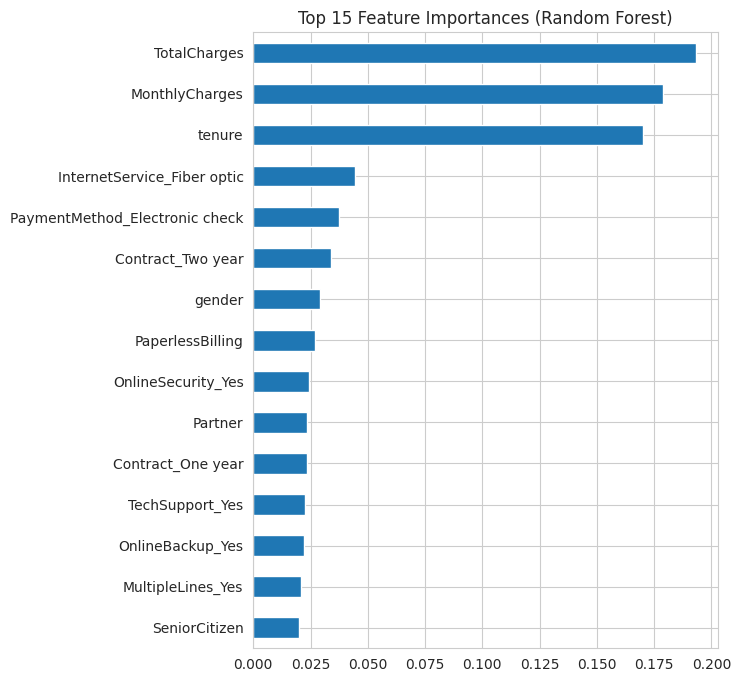

RFE selected features:
 ['tenure', 'MonthlyCharges', 'TotalCharges', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year']


In [ ]:
# ============================================
# STEP 5: Feature Selection
# ============================================
from sklearn.feature_selection import RFE

# TODO 1: Fix multicollinearity — drop the duplicate "No internet service" columns
# Keep only ONE signal for "no internet" (InternetService_No already captures this),
# the other 6 columns saying the same thing are redundant and should be dropped
redundant_cols = ['StreamingTV_No internet service', 'OnlineSecurity_No internet service',
                   'OnlineBackup_No internet service', 'DeviceProtection_No internet service',
                   'StreamingMovies_No internet service', 'TechSupport_No internet service']

X_train = X_train.drop(columns=redundant_cols)
X_test = X_test.drop(columns=redundant_cols)

# TODO 2: Re-scale after dropping columns (column set changed, so re-fit the scaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# TODO 3: EMBEDDED METHOD — Random Forest feature importance
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_scaled, y_train)

importances = pd.Series(rf.feature_importances_, index=X_train.columns)
importances = importances.sort_values(ascending=False)

plt.figure(figsize=(6,8))
importances.head(15).plot(kind='barh')
plt.title("Top 15 Feature Importances (Random Forest)")
plt.gca().invert_yaxis()
plt.show()

# TODO 4: WRAPPER METHOD — RFE with Logistic Regression, select top 10 features
lr = LogisticRegression(max_iter=1000, random_state=42)
rfe = RFE(estimator=lr, n_features_to_select=10)
rfe.fit(X_train_scaled, y_train)

selected_features_rfe = X_train.columns[rfe.support_]
print("RFE selected features:\n", selected_features_rfe.tolist())

# TODO 5: Compare — does 'tenure' and 'Contract' show up in BOTH the RF importance top 10
# AND the RFE selected list? (they should — that's a strong signal these are genuinely important,
# not just an artifact of one algorithm's bias)

Original feature count: 24
PCA components used: 18


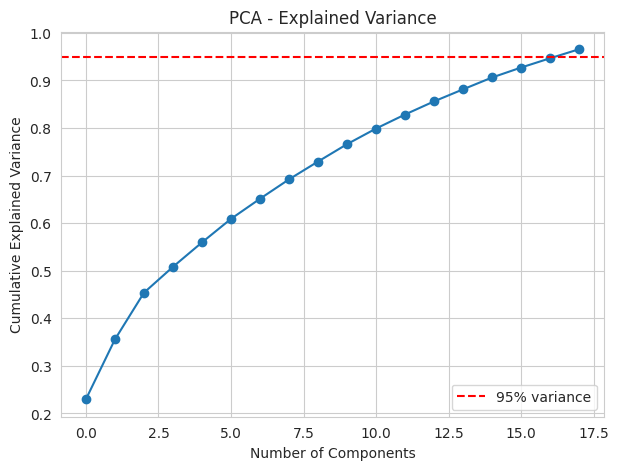

                Full Features  PCA Features
Num Features          24.0000       18.0000
Accuracy               0.8077        0.7942
ROC-AUC                0.8421        0.8371
Train Time (s)         0.1888        0.0649


In [ ]:
# ============================================
# STEP 6: PCA vs Full Features — accuracy & speed tradeoff
# ============================================
from sklearn.decomposition import PCA
import time

# TODO 1: Fit PCA on the scaled training data. Start by keeping enough components
# to explain 95% of variance (a standard rule of thumb)
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# TODO 2: How many components did PCA actually need to reach 95% variance?
print("Original feature count:", X_train_scaled.shape[1])
print("PCA components used:", pca.n_components_)

# TODO 3: Plot cumulative explained variance (connects back to Day 17-18 eigenvalues/SVD)
plt.figure(figsize=(7,5))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.axhline(y=0.95, color='r', linestyle='--', label='95% variance')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Explained Variance")
plt.legend()
plt.show()

# TODO 4: Train Logistic Regression on FULL features — time it
start = time.time()
lr_full = LogisticRegression(max_iter=1000, random_state=42)
lr_full.fit(X_train_scaled, y_train)
time_full = time.time() - start

acc_full = lr_full.score(X_test_scaled, y_test)
auc_full = roc_auc_score(y_test, lr_full.predict_proba(X_test_scaled)[:, 1])

# TODO 5: Train Logistic Regression on PCA-REDUCED features — time it
start = time.time()
lr_pca = LogisticRegression(max_iter=1000, random_state=42)
lr_pca.fit(X_train_pca, y_train)
time_pca = time.time() - start

acc_pca = lr_pca.score(X_test_pca, y_test)
auc_pca = roc_auc_score(y_test, lr_pca.predict_proba(X_test_pca)[:, 1])

# TODO 6: Compare in a clean table
comparison = pd.DataFrame({
    "Full Features": [X_train_scaled.shape[1], acc_full, auc_full, time_full],
    "PCA Features": [X_train_pca.shape[1], acc_pca, auc_pca, time_pca]
}, index=["Num Features", "Accuracy", "ROC-AUC", "Train Time (s)"])

print(comparison.round(4))

In [ ]:
# ============================================
# STEP 7: Cross-Validation + Hyperparameter Tuning
# ============================================
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier

# TODO 1: Define a Stratified K-Fold cross-validator (5 folds)
# Stratified = preserves the 26.54% churn ratio in EVERY fold, same reasoning as our train/test split
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ---------- Tune Logistic Regression ----------
# TODO 2: Define hyperparameter grid for Logistic Regression
# C = inverse of regularization strength (smaller C = stronger regularization, like Ridge's lambda from Day 6)
lr_param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']   # liblinear supports both l1 and l2
}

lr_grid = GridSearchCV(
    estimator=LogisticRegression(max_iter=1000, random_state=42),
    param_grid=lr_param_grid,
    cv=cv,
    scoring='roc_auc',     # optimize for ROC-AUC, not accuracy, because data is imbalanced
    n_jobs=-1               # use all CPU cores in parallel
)
lr_grid.fit(X_train_scaled, y_train)

print("Best LR params:", lr_grid.best_params_)
print("Best LR CV ROC-AUC:", lr_grid.best_score_)

# ---------- Tune Random Forest ----------
# TODO 3: Define hyperparameter grid for Random Forest
# max_depth controls overfitting (recall Day 7 bias-variance tradeoff — deep trees = low bias, high variance)
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=rf_param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)
rf_grid.fit(X_train_scaled, y_train)

print("Best RF params:", rf_grid.best_params_)
print("Best RF CV ROC-AUC:", rf_grid.best_score_)

# ---------- Try Gradient Boosting (new algorithm) ----------
# TODO 4: Define a small hyperparameter grid for Gradient Boosting
gb_param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5]
}

gb_grid = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_grid=gb_param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)
gb_grid.fit(X_train_scaled, y_train)

print("Best GB params:", gb_grid.best_params_)
print("Best GB CV ROC-AUC:", gb_grid.best_score_)

# TODO 5: Compare all three tuned models on the TEST set (final, unbiased check)
final_models = {
    "Logistic Regression (tuned)": lr_grid.best_estimator_,
    "Random Forest (tuned)": rf_grid.best_estimator_,
    "Gradient Boosting (tuned)": gb_grid.best_estimator_
}

final_results = {}
for name, model in final_models.items():
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    y_pred = model.predict(X_test_scaled)
    final_results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    }

final_results_df = pd.DataFrame(final_results).T
print(final_results_df.round(4))

Best LR params: {'C': 100, 'penalty': 'l2', 'solver': 'liblinear'}
Best LR CV ROC-AUC: 0.8463550906036671
Best RF params: {'max_depth': 5, 'min_samples_split': 10, 'n_estimators': 200}
Best RF CV ROC-AUC: 0.8464048097517283
Best GB params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
Best GB CV ROC-AUC: 0.8474548510417333
                             Accuracy  Recall  Precision  ROC-AUC
Logistic Regression (tuned)    0.8013  0.5508     0.6478   0.8408
Random Forest (tuned)          0.7899  0.3984     0.6773   0.8444
Gradient Boosting (tuned)      0.7984  0.5080     0.6552   0.8417


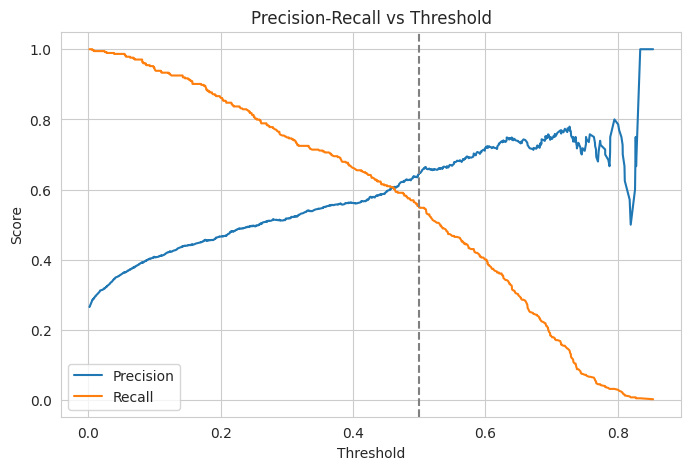

=== Default threshold (0.5) ===
Recall: 0.5508021390374331
Precision: 0.6477987421383647

=== Custom threshold (0.3) ===
Recall: 0.7486631016042781
Precision: 0.5175600739371534
Accuracy: 0.7480482611781405


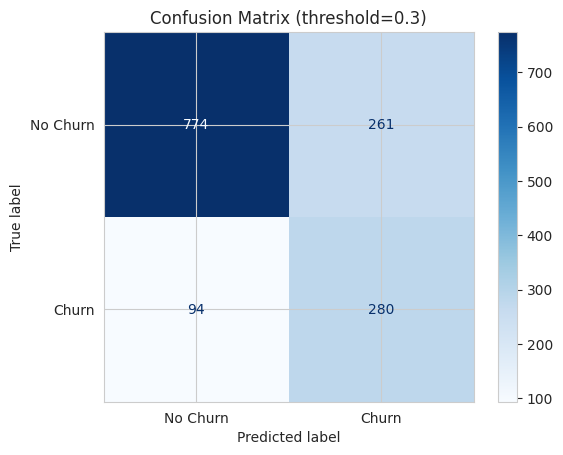

In [ ]:
# ============================================
# STEP 8: Threshold Tuning for Recall
# ============================================
from sklearn.metrics import precision_recall_curve

# TODO 1: Get our final chosen model
final_model = lr_grid.best_estimator_

# TODO 2: Get predicted probabilities on test set
y_proba_final = final_model.predict_proba(X_test_scaled)[:, 1]

# TODO 3: Compute precision, recall at EVERY possible threshold
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba_final)

# TODO 4: Plot Precision and Recall vs Threshold — visualize the tradeoff
plt.figure(figsize=(8,5))
plt.plot(thresholds, precisions[:-1], label='Precision')
plt.plot(thresholds, recalls[:-1], label='Recall')
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision-Recall vs Threshold")
plt.legend()
plt.axvline(x=0.5, color='gray', linestyle='--', label='Default threshold')
plt.show()

# TODO 5: Pick a lower threshold (e.g., 0.3) to prioritize Recall, then recompute metrics
custom_threshold = 0.3
y_pred_custom = (y_proba_final >= custom_threshold).astype(int)

print("=== Default threshold (0.5) ===")
print("Recall:", recall_score(y_test, final_model.predict(X_test_scaled)))
print("Precision:", precision_score(y_test, final_model.predict(X_test_scaled)))

print(f"\n=== Custom threshold ({custom_threshold}) ===")
print("Recall:", recall_score(y_test, y_pred_custom))
print("Precision:", precision_score(y_test, y_pred_custom))
print("Accuracy:", accuracy_score(y_test, y_pred_custom))

# TODO 6: Confusion matrix at the new threshold — see the actual tradeoff in raw numbers
cm = confusion_matrix(y_test, y_pred_custom)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
disp.plot(cmap='Blues')
plt.title(f"Confusion Matrix (threshold={custom_threshold})")
plt.show()

In [ ]:
# ============================================
# STEP 9: Save Model + Scaler + Column Structure
# ============================================
import joblib

# TODO 1: Save the final trained Logistic Regression model
joblib.dump(lr_grid, 'churn_model.pkl')

# TODO 2: Save the fitted scaler (needed to transform new raw user input the same way)
joblib.dump(scaler, 'scaler.pkl')

# TODO 3: Save the exact column order X_train has AFTER encoding
# (Streamlit will build a dataframe from user input and MUST match this exact column order)
model_columns = X_train.columns.tolist()
joblib.dump(model_columns, 'model_columns.pkl')

# TODO 4: Save the chosen threshold too, so the app uses 0.3, not the sklearn default 0.5
joblib.dump(0.3, 'threshold.pkl')

print("Saved: churn_model.pkl, scaler.pkl, model_columns.pkl, threshold.pkl")

Saved: churn_model.pkl, scaler.pkl, model_columns.pkl, threshold.pkl


In [ ]:
!pip install streamlit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 45.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 68.7 MB/s eta 0:00:00


In [ ]:
import streamlit as st
import pandas as pd
import numpy as np
import joblib

# ============================================
# Load saved artifacts
# ============================================
# TODO 1: Load the 4 files we saved (model, scaler, column list, threshold)
model = joblib.load('churn_model.pkl')
scaler = joblib.load('scaler.pkl')
model_columns = joblib.load('model_columns.pkl')
threshold = joblib.load('threshold.pkl')

st.set_page_config(page_title="Customer Churn Predictor", page_icon="📉", layout="centered")
st.title("Customer Churn Prediction")
st.markdown("Enter customer details to predict churn risk.")

# ============================================
# Collect user input (this part is given — pure UI, no ML logic)
# ============================================
col1, col2 = st.columns(2)

with col1:
    gender = st.selectbox("Gender", ["Male", "Female"])
    senior_citizen = st.selectbox("Senior Citizen", ["No", "Yes"])
    partner = st.selectbox("Has Partner", ["No", "Yes"])
    dependents = st.selectbox("Has Dependents", ["No", "Yes"])
    tenure = st.slider("Tenure (months)", 0, 72, 12)
    phone_service = st.selectbox("Phone Service", ["No", "Yes"])
    paperless_billing = st.selectbox("Paperless Billing", ["No", "Yes"])
    contract = st.selectbox("Contract", ["Month-to-month", "One year", "Two year"])

with col2:
    multiple_lines = st.selectbox("Multiple Lines", ["No", "Yes", "No phone service"])
    internet_service = st.selectbox("Internet Service", ["DSL", "Fiber optic", "No"])
    online_security = st.selectbox("Online Security", ["No", "Yes", "No internet service"])
    online_backup = st.selectbox("Online Backup", ["No", "Yes", "No internet service"])
    device_protection = st.selectbox("Device Protection", ["No", "Yes", "No internet service"])
    tech_support = st.selectbox("Tech Support", ["No", "Yes", "No internet service"])
    streaming_tv = st.selectbox("Streaming TV", ["No", "Yes", "No internet service"])
    streaming_movies = st.selectbox("Streaming Movies", ["No", "Yes", "No internet service"])

payment_method = st.selectbox("Payment Method",
    ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"])
monthly_charges = st.number_input("Monthly Charges ($)", min_value=0.0, max_value=200.0, value=70.0)
total_charges = st.number_input("Total Charges ($)", min_value=0.0, max_value=10000.0, value=840.0)

# ============================================
# Build the raw input dataframe (mirrors the ORIGINAL df structure before encoding)
# ============================================
if st.button("Predict Churn"):

    # TODO 2: Build a single-row dict matching the ORIGINAL raw column names
    # (same names/values as your df BEFORE encoding — LabelEncoder used 0/1, get_dummies used raw category text)
    raw_input = {
        'gender': 1 if gender == "Male" else 0,   # matches how LabelEncoder encoded it during training
        'SeniorCitizen': 1 if senior_citizen == "Yes" else 0,
        'Partner': 1 if partner == "Yes" else 0,   # same pattern as gender/SeniorCitizen above
        'Dependents': 1 if dependents == "Yes" else 0,
        'tenure': tenure,
        'PhoneService': 1 if phone_service == "Yes" else 0,
        'PaperlessBilling': 1 if paperless_billing == "Yes" else 0,
        'MonthlyCharges': monthly_charges,
        'TotalCharges': total_charges,
        'MultipleLines': multiple_lines,             # raw text — will be one-hot encoded below
        'InternetService': internet_service,
        'OnlineSecurity': online_security,
        'OnlineBackup': online_backup,
        'DeviceProtection': device_protection,
        'TechSupport': tech_support,
        'StreamingTV': streaming_tv,
        'StreamingMovies': streaming_movies,
        'Contract': contract,
        'PaymentMethod': payment_method
    }

    input_df = pd.DataFrame([raw_input])

    # TODO 3: One-hot encode the same multi-category columns we encoded during training
    multi_cat_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
                       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
                       'Contract', 'PaymentMethod']

    input_encoded = pd.get_dummies(input_df, columns=multi_cat_cols)

    # TODO 4: THE CRITICAL STEP — align columns to match training exactly
    # Any column the model expects but this row doesn't have gets filled with 0
    # Any extra column not seen during training gets dropped
    input_final = input_encoded.reindex(columns=model_columns, fill_value=0)

    # TODO 5: Scale using the SAME fitted scaler from training (never re-fit here!)
    input_scaled = scaler.transform(input_final)

    # TODO 6: Predict probability of churn (class 1)
    churn_proba = model.predict_proba(input_scaled)[:, 1][0]

    # TODO 7: Apply our chosen threshold (0.3, not sklearn's default 0.5)
    prediction = 1 if churn_proba >= threshold else 0

    # ============================================
    # Display results (given — pure UI)
    # ============================================
    st.divider()
    if prediction == 1:
        st.error(f"⚠️ High Churn Risk — Probability: {churn_proba:.1%}")
        st.write("**Recommendation:** Consider proactive retention offer (discount, contract upgrade incentive).")
    else:
        st.success(f"✅ Low Churn Risk — Probability: {churn_proba:.1%}")

    st.progress(min(float(churn_proba), 1.0))
    st.caption(f"Decision threshold: {threshold} (tuned for higher recall — catches more true churners)")

2026-08-03 10:35:08.852 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-03 10:35:08.854 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-03 10:35:09.045 
  command:

    streamlit run /usr/local/lib/python3.12/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-08-03 10:35:09.046 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-03 10:35:09.047 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-03 10:35:09.049 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-03 10:35:09.049 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when runn

In [ ]:
# Run this in Colab, not Streamlit — just to generate a few "known answer" test cases
sample = X_test.copy()
sample['Actual_Churn'] = y_test.values
sample_check = sample.sample(5, random_state=1)
print(sample_check)

      gender  SeniorCitizen  Partner  Dependents  tenure  PhoneService  \
126        0              1        0           0      27             1   
4017       0              0        0           0      28             1   
5860       0              0        0           0       2             1   
4114       0              0        1           1      51             1   
3790       1              0        0           0       2             1   

      PaperlessBilling  MonthlyCharges  TotalCharges  \
126                  1           78.05       2135.50   
4017                 0           59.00       1654.45   
5860                 0           70.00        153.05   
4114                 0           19.95       1028.75   
3790                 0           19.30         28.30   

      MultipleLines_No phone service  ...  DeviceProtection_Yes  \
126                            False  ...                  True   
4017                           False  ...                  True   
5860             